# 02 · Métodos de reducción de dimensionalidad
Comparación de PCA, Isomap, t-SNE y UMAP.Primero sobre el swiss roll (datos de prueba) y después sobre los hogares.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap, TSNE, trustworthiness
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
import umap

SEED = 42

(1500, 3)


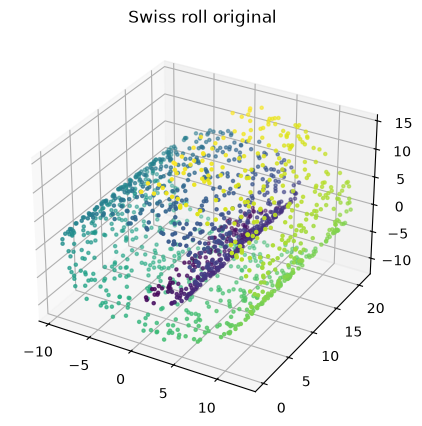

In [3]:
X, t = make_swiss_roll(n_samples=1500, noise=0.05, random_state=SEED)
print(X.shape)

fig = plt.figure(figsize=(6,5))
ax= fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap="viridis", s=5)
ax.set_title("Swiss roll original")
plt.show()

In [18]:
# PCA: busca las 2 direcciones donde los datos esten mas dispersos
pca = PCA(n_components=2)
Y_pca = pca.fit_transform(X)

# Isomap: 10 vecinos mas cercanos como por carretera
isomap = Isomap(n_neighbors=10, n_components=2)
Y_isomap = isomap.fit_transform(X)

# t-SNE: intenta que los vecinos cercanos en el 3D sigan siendolo en el 2D y lo de perplexity son los vecinos consideran los nodos
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED)
Y_tsne = tsne.fit_transform(X)

# UMAP: es uan mezcla de la red de vecinos de isomap y colocalr los puntos en el 2D como t-SNE
modelo_umap = umap.UMAP(n_neighbors=15, n_components=2, random_state=SEED, compatibility_layout=True)
Y_umap = modelo_umap.fit_transform(X)

print(Y_pca.shape, Y_isomap.shape, Y_tsne.shape, Y_umap.shape)

c:\Users\ringo\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(1500, 2) (1500, 2) (1500, 2) (1500, 2)


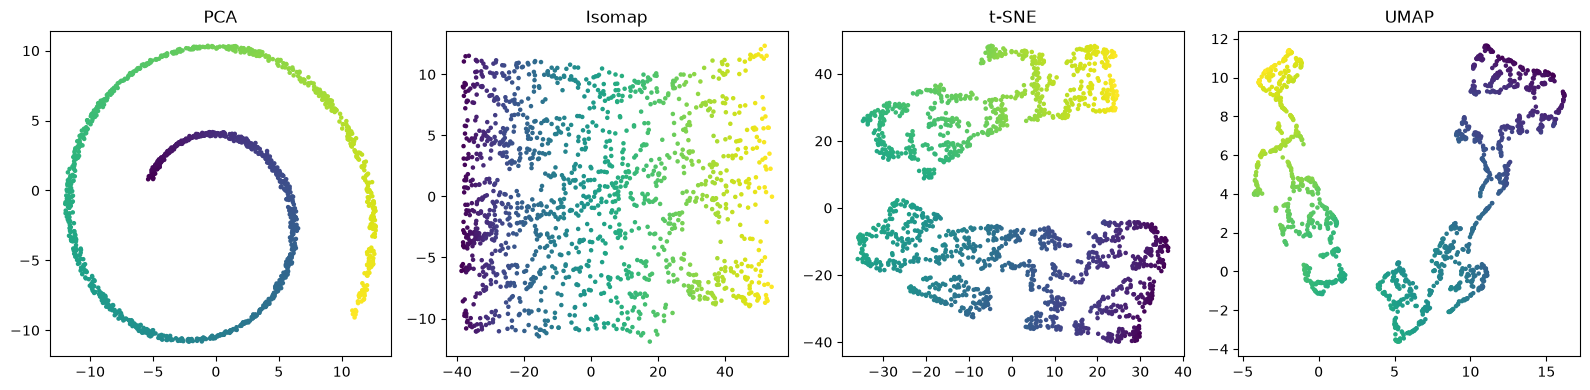

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].scatter(Y_pca[:, 0], Y_pca[:, 1], c=t, cmap="viridis", s=5)
axes[0].set_title("PCA")

axes[1].scatter(Y_isomap[:, 0], Y_isomap[:, 1], c=t, cmap="viridis", s=5)
axes[1].set_title("Isomap")

axes[2].scatter(Y_tsne[:, 0], Y_tsne[:, 1], c=t, cmap="viridis", s=5)
axes[2].set_title("t-SNE")

axes[3].scatter(Y_umap[:, 0], Y_umap[:, 1], c=t, cmap="viridis", s=5)
axes[3].set_title("UMAP")

plt.tight_layout()
plt.show()

In [15]:
def correlacion_distancias(X, Y):
    d_original = pdist(X)
    d_mapa = pdist(Y)
    return spearmanr(d_original, d_mapa).correlation

print("Funciones listas")

Funciones listas


In [19]:
print("PCA      | confianza:", round(trustworthiness(X, Y_pca, n_neighbors=10), 3),
      "| distancias:", round(correlacion_distancias(X, Y_pca), 3))
print("Isomap   | confianza:", round(trustworthiness(X, Y_isomap, n_neighbors=10), 3),
      "| distancias:", round(correlacion_distancias(X, Y_isomap), 3))
print("t-SNE    | confianza:", round(trustworthiness(X, Y_tsne, n_neighbors=10), 3),
      "| distancias:", round(correlacion_distancias(X, Y_tsne), 3))
print("UMAP     | cinfianza:", round(trustworthiness(X, Y_umap, n_neighbors=10), 3),
      "| distancias:", round(correlacion_distancias(X, Y_umap), 3))

PCA      | confianza: 0.897 | distancias: 0.848
Isomap   | confianza: 1.0 | distancias: 0.362
t-SNE    | confianza: 1.0 | distancias: 0.349
UMAP     | cinfianza: 0.999 | distancias: 0.277


In [20]:
resultados = pd.DataFrame({
    "metodo": ["PCA", "Isomap", "t-SNE", "UMAP"],
    "confianza": [trustworthiness(X, Y_pca, n_neighbors=10),
                  trustworthiness(X, Y_isomap, n_neighbors=10),
                  trustworthiness(X, Y_tsne, n_neighbors=10),
                  trustworthiness(X, Y_umap, n_neighbors=10)],
    "distancias": [correlacion_distancias(X, Y_pca),
                   correlacion_distancias(X, Y_isomap),
                   correlacion_distancias(X, Y_tsne),
                   correlacion_distancias(X, Y_umap)],
}).round(3)

resultados

,metodo,confianza,distancias
0,PCA,0.897,0.848
1,Isomap,1.000,0.362
2,t-SNE,1.000,0.349
3,UMAP,0.999,0.277
